# Tugas Praktikum 3 Ensemble Method dan Class Imbalance
**Studi kasus:** deteksi penipuan transaksi kartu kredit.  
**Nama:** Prima Surya Nusantara  
**NRP:** 5054251036

## 1 Unduh dan import dataset


In [1]:
from pathlib import Path
from time import perf_counter
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve)

SEED = 42
THRESHOLD = 0.5
OUTPUT_DIR = Path('hasil_ensemble')
OUTPUT_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 180})


In [2]:
SUMBER = "creditcard.csv"
df = pd.read_csv(SUMBER)
print('Ukuran dataset awal:', df.shape)
display(df.head())
df.info()

Ukuran dataset awal: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

## 2 Praproses data
### 2.1 Distribusi kelas dan pemeriksaan kualitas
Distribusi awal dihitung sebelum penghapusan duplikat agar tetap sesuai dengan dataset asli dalam instruksi. Tidak ada resampling pada tahap ini.


,Kelas,Jumlah,Persentase
0,Normal,284315,99.827251
1,Fraud,492,0.172749


Total nilai kosong: 0
Baris duplikat persis: 1081
Jumlah tipe data:
float64    30
int64       1
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16


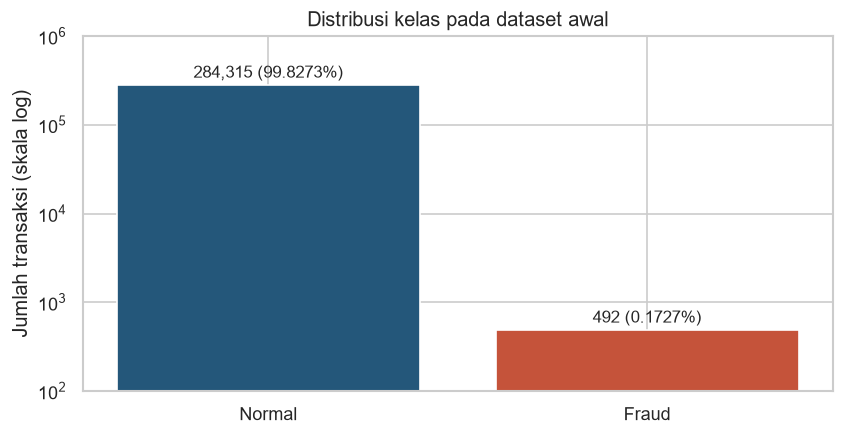

In [3]:
def class_distribution(y):
    counts = y.value_counts().reindex([0, 1], fill_value=0)
    return pd.DataFrame({'Kelas': ['Normal', 'Fraud'], 'Jumlah': counts.values,
                         'Persentase': (counts / len(y) * 100).values}, index=[0, 1])
initial_distribution = class_distribution(df['Class'])
display(initial_distribution.round(6))
missing_total = int(df.isna().sum().sum())
duplicate_total = int(df.duplicated().sum())
print('Total nilai kosong:', missing_total)
print('Baris duplikat persis:', duplicate_total)
print('Jumlah tipe data:')
print(df.dtypes.value_counts())
display(df[['Time', 'Amount']].describe().T)
assert set(df['Class'].unique()) == {0, 1}
assert df.shape[1] == 31
assert np.isfinite(df.to_numpy()).all()

fig, ax = plt.subplots(figsize=(7.2, 3.8))
bars = ax.bar(initial_distribution['Kelas'], initial_distribution['Jumlah'],
              color=['#24577A', '#C5533A'])
ax.set_yscale('log')
ax.set_ylim(100, 1000000)
ax.set_ylabel('Jumlah transaksi (skala log)')
ax.set_title('Distribusi kelas pada dataset awal')
for bar, count, pct in zip(bars, initial_distribution['Jumlah'], initial_distribution['Persentase']):
    ax.text(bar.get_x()+bar.get_width()/2, count*1.2,
            f'{count:,} ({pct:.4f}%)', ha='center', fontsize=10)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '01_distribusi_awal.png')
plt.show()


### 2.2 Pembersihan

In [4]:
df_clean = df.drop_duplicates().reset_index(drop=True)
print('Dataset sebelum pembersihan:', df.shape)
print('Dataset setelah pembersihan:', df_clean.shape)
display(class_distribution(df_clean['Class']).round(6))
X = df_clean.drop(columns='Class')
y = df_clean['Class']
assert X.shape[1] == 30
assert not df_clean.duplicated().any()


Dataset sebelum pembersihan: (284807, 31)
Dataset setelah pembersihan: (283726, 31)


,Kelas,Jumlah,Persentase
0,Normal,283253,99.83329
1,Fraud,473,0.16671


### 2.3 Pembagian data latih dan uji 80 banding 20

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
split_table = pd.DataFrame({
    'Total': [len(y_train), len(y_test)],
    'Normal': [(y_train == 0).sum(), (y_test == 0).sum()],
    'Fraud': [(y_train == 1).sum(), (y_test == 1).sum()],
    'Fraud persen': [y_train.mean()*100, y_test.mean()*100]
}, index=['Latih', 'Uji'])
display(split_table.round(6))
assert set(X_train.index).isdisjoint(X_test.index)
test_index_before = X_test.index.copy()
y_test_before = y_test.copy(deep=True)


,Total,Normal,Fraud,Fraud persen
Latih,226980,226602,378,0.166534
Uji,56746,56651,95,0.167413


### 2.4 Random undersampling hanya pada data latih
Random undersampling mengambil sebagian kelas normal secara acak **tanpa pengembalian**, sambil mempertahankan seluruh fraud dalam data latih. Implementasi menggunakan `pandas.sample` sehingga tidak memerlukan paket tambahan. Sebutan **1:10** berarti **1 fraud untuk 10 normal**, bukan sebaliknya.

Keuntungan: jumlah fraud relatif lebih terlihat oleh model dan pelatihan menjadi lebih ringan. Kekurangan: sebagian besar contoh normal tidak digunakan sehingga false positive dapat meningkat. Rasio 1:10 menangani ketimpangan tanpa memaksakan keseimbangan penuh; rasio 1:1 memperlihatkan dampak keseimbangan penuh.


,Normal,Fraud,Total,Fraud persen
Skenario,,,,
RF tanpa resampling,226602,378,226980,0.1665
RF RUS 1:10,3780,378,4158,9.0909
RF RUS 1:1,378,378,756,50.0000


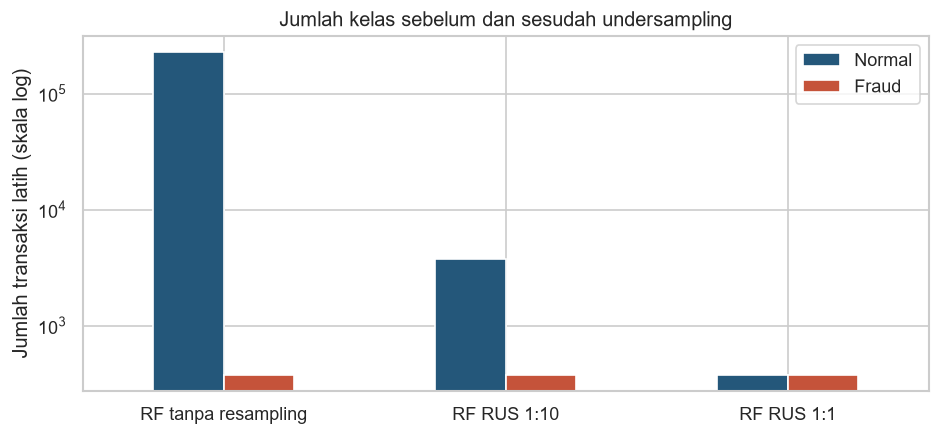

In [6]:
def random_undersample(X_train, y_train, normal_per_fraud, random_state=42):
    fraud_index = y_train[y_train == 1].index
    normal_index = y_train[y_train == 0].index
    n_normal = min(len(normal_index), int(len(fraud_index) * normal_per_fraud))
    selected_normal = pd.Series(normal_index).sample(n=n_normal, replace=False,
                                                   random_state=random_state).to_numpy()
    selected_index = np.concatenate([selected_normal, fraud_index.to_numpy()])
    np.random.default_rng(random_state).shuffle(selected_index)
    return X_train.loc[selected_index].copy(), y_train.loc[selected_index].copy()

X_rus10, y_rus10 = random_undersample(X_train, y_train, 10, SEED)
X_rus1, y_rus1 = random_undersample(X_train, y_train, 1, SEED)
training_sets = {'RF tanpa resampling': (X_train, y_train),
                 'RF RUS 1:10': (X_rus10, y_rus10),
                 'RF RUS 1:1': (X_rus1, y_rus1)}
resampling_table = pd.DataFrame([
    {'Skenario': name, 'Normal': int((ys == 0).sum()),
     'Fraud': int((ys == 1).sum()), 'Total': len(ys),
     'Fraud persen': ys.mean()*100}
    for name, (xs, ys) in training_sets.items()]).set_index('Skenario')
display(resampling_table.round(4))
for xs, ys in [(X_rus10, y_rus10), (X_rus1, y_rus1)]:
    assert set(xs.index).issubset(X_train.index)
    assert set(xs.index).isdisjoint(X_test.index)
    assert (ys == 1).sum() == (y_train == 1).sum()
    assert xs.index.is_unique
pd.testing.assert_series_equal(y_test, y_test_before)
assert X_test.index.equals(test_index_before)

fig, ax = plt.subplots(figsize=(8, 3.8))
resampling_table[['Normal', 'Fraud']].plot.bar(ax=ax, color=['#24577A', '#C5533A'])
ax.set_yscale('log')
ax.set_ylabel('Jumlah transaksi latih (skala log)')
ax.set_title('Jumlah kelas sebelum dan sesudah undersampling')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=0)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '02_resampling.png')
plt.show()


## 3 Membangun model klasifikasi ensemble
Random Forest menggabungkan banyak pohon keputusan dari sampel bootstrap dan subset fitur acak. Pada klasifikasi, probabilitas kelas dirata-ratakan dari pohon-pohon tersebut. Seluruh skenario menggunakan parameter sama: 100 pohon, Gini, `max_features='sqrt'`, tanpa batas kedalaman, `min_samples_leaf=1`, dan `class_weight=None`. Perbedaan eksperimen terletak pada data latih.

`n_jobs=4` membatasi penggunaan CPU; dapat diubah sesuai perangkat. `random_state=42` menjaga pengacakan dapat direproduksi. Threshold 0,5 digunakan pada seluruh skenario tanpa tuning. Waktu pelatihan bersifat tergantung perangkat, bukan ukuran kualitas prediksi.


In [7]:
models, probabilities, predictions = {}, {}, {}
fit_times = {}
for name, (xs, ys) in training_sets.items():
    print('Melatih:', name, '| ukuran:', xs.shape, flush=True)
    model = RandomForestClassifier(n_estimators=100, criterion='gini',
        max_features='sqrt', max_depth=None, min_samples_leaf=1,
        class_weight=None, bootstrap=True, random_state=SEED, n_jobs=4)
    start = perf_counter()
    model.fit(xs, ys)
    fit_times[name] = perf_counter() - start
    fraud_col = np.flatnonzero(model.classes_ == 1)[0]
    proba = model.predict_proba(X_test)[:, fraud_col]
    models[name] = model
    probabilities[name] = proba
    predictions[name] = (proba >= THRESHOLD).astype(int)
    print(f'Selesai dalam {fit_times[name]:.2f} detik', flush=True)


Melatih: RF tanpa resampling | ukuran: (226980, 30)
Selesai dalam 58.88 detik
Melatih: RF RUS 1:10 | ukuran: (4158, 30)
Selesai dalam 0.47 detik
Melatih: RF RUS 1:1 | ukuran: (756, 30)
Selesai dalam 0.16 detik


## 4 Evaluasi model
### 4.1 Metrik untuk kelas fraud

In [8]:
def evaluate_predictions(name, y_true, y_pred, scores, fit_seconds=0):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {'Model': name, 'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'Recall': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'F1': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        'ROC_AUC': roc_auc_score(y_true, scores),
        'AP': average_precision_score(y_true, scores),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
        'Fit_detik': fit_seconds}

rows = [evaluate_predictions(name, y_test, predictions[name], probabilities[name],
                             fit_times[name]) for name in models]
results = pd.DataFrame(rows).set_index('Model')
display(results.round(6))
for name in models:
    print('\n' + name)
    print(classification_report(y_test, predictions[name], labels=[0, 1],
          target_names=['Normal', 'Fraud'], digits=4, zero_division=0))
results.to_csv(OUTPUT_DIR / 'hasil_evaluasi.csv')
assert all(results[['TN', 'FP', 'FN', 'TP']].sum(axis=1) == len(y_test))


,Accuracy,Precision,Recall,F1,ROC_AUC,AP,TN,FP,FN,TP,Fit_detik
Model,,,,,,,,,,,
RF tanpa resampling,0.999507,0.971831,0.726316,0.831325,0.923944,0.787581,56649,2,26,69,58.879253
RF RUS 1:10,0.998308,0.496689,0.789474,0.609756,0.969816,0.694128,56575,76,20,75,0.471090
RF RUS 1:1,0.983576,0.082752,0.873684,0.151184,0.973274,0.715287,55731,920,12,83,0.163909



RF tanpa resampling
              precision    recall  f1-score   support

      Normal     0.9995    1.0000    0.9998     56651
       Fraud     0.9718    0.7263    0.8313        95

    accuracy                         0.9995     56746
   macro avg     0.9857    0.8631    0.9155     56746
weighted avg     0.9995    0.9995    0.9995     56746


RF RUS 1:10
              precision    recall  f1-score   support

      Normal     0.9996    0.9987    0.9992     56651
       Fraud     0.4967    0.7895    0.6098        95

    accuracy                         0.9983     56746
   macro avg     0.7482    0.8941    0.8045     56746
weighted avg     0.9988    0.9983    0.9985     56746


RF RUS 1:1
              precision    recall  f1-score   support

      Normal     0.9998    0.9838    0.9917     56651
       Fraud     0.0828    0.8737    0.1512        95

    accuracy                         0.9836     56746
   macro avg     0.5413    0.9287    0.5714     56746
weighted avg     0.9982    0

### 4.2 Confusion matrix dan perbandingan metrik
Sumbu baris adalah kelas aktual dan sumbu kolom adalah kelas prediksi. Perhatikan perubahan FP dan FN, bukan hanya jumlah TN yang sangat besar.


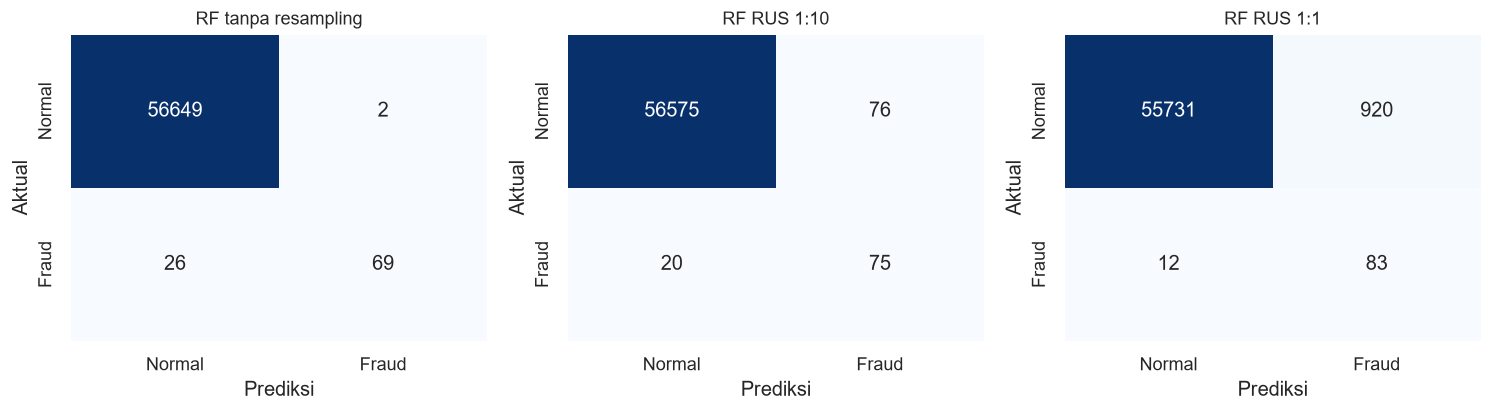

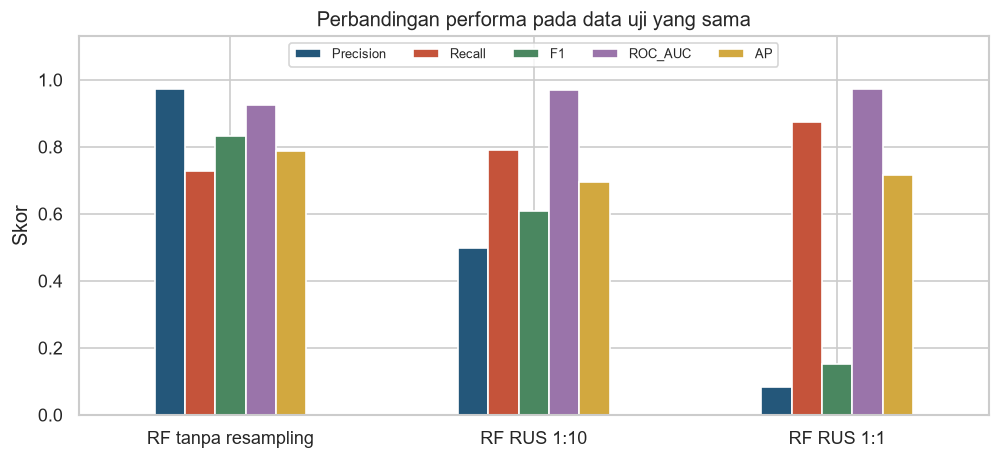

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.6))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, predictions[name], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Normal', 'Fraud'], yticklabels=['Normal', 'Fraud'], ax=ax)
    ax.set_title(name, fontsize=11)
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '03_confusion_matrix.png')
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 4))
results[['Precision', 'Recall', 'F1', 'ROC_AUC', 'AP']].plot.bar(ax=ax,
    color=['#24577A', '#C5533A', '#4A8760', '#9A74AA', '#D2A83F'])
ax.set_ylim(0, 1.13)
ax.set_ylabel('Skor')
ax.set_xlabel('')
ax.set_title('Perbandingan performa pada data uji yang sama')
ax.tick_params(axis='x', rotation=0)
ax.legend(ncol=5, fontsize=8, loc='upper center')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '04_perbandingan_metrik.png')
plt.show()


### 4.3 Kurva ROC dan precision recall
Kurva memakai probabilitas fraud. Garis diagonal ROC adalah referensi pengurutan acak (AUC 0,5). Garis horizontal PR adalah prevalensi fraud pada data uji, sebagai referensi skor yang tidak informatif. Kurva tidak digunakan untuk memilih threshold dari data uji.


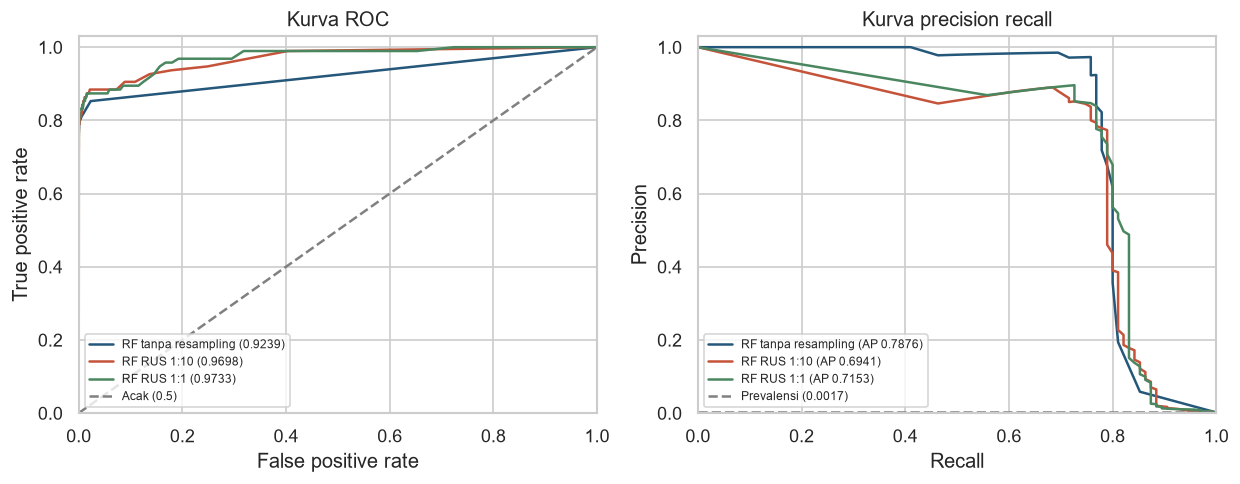

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
colors = ['#24577A', '#C5533A', '#4A8760']
for name, color in zip(models, colors):
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    prec, rec, _ = precision_recall_curve(y_test, probabilities[name])
    axes[0].plot(fpr, tpr, label=f'{name} ({results.loc[name, "ROC_AUC"]:.4f})', color=color)
    axes[1].plot(rec, prec, label=f'{name} (AP {results.loc[name, "AP"]:.4f})', color=color)
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Acak (0.5)')
axes[1].axhline(y_test.mean(), ls='--', color='gray', label=f'Prevalensi ({y_test.mean():.4f})')
axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='Kurva ROC')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Kurva precision recall')
for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.03)
    ax.legend(fontsize=7, loc='lower left')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '05_kurva.png')
plt.show()


### 4.4 Mengapa accuracy saja tidak cukup
Pembanding `DummyClassifier` selalu memprediksi normal. Model ini bisa menghasilkan accuracy sangat tinggi walaupun tidak mendeteksi satu fraud pun. AP untuk skor konstan sama dengan prevalensi fraud; ROC-AUC-nya 0,5.


In [11]:
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
dummy_proba = dummy.predict_proba(X_test)[:, np.flatnonzero(dummy.classes_ == 1)[0]]
dummy_result = evaluate_predictions('Selalu normal', y_test, dummy_pred, dummy_proba)
display(pd.DataFrame([dummy_result]).set_index('Model').round(6))
print(f'Accuracy selalu normal: {dummy_result["Accuracy"]:.4%}')
print(f'Recall fraud: {dummy_result["Recall"]:.4%}; fraud terlewat: {dummy_result["FN"]}')


,Accuracy,Precision,Recall,F1,ROC_AUC,AP,TN,FP,FN,TP,Fit_detik
Model,,,,,,,,,,,
Selalu normal,0.998326,0.0,0.0,0.0,0.5,0.001674,56651,0,95,0,0


Accuracy selalu normal: 99.8326%
Recall fraud: 0.0000%; fraud terlewat: 95


## 5 Analisis hasil eksperimen
Teks berikut dihitung dari hasil aktual. Kenaikan recall berarti lebih sedikit fraud terlewat, tetapi perlu diperiksa bersama FP, precision, dan F1. Undersampling tidak dijamin meningkatkan semua metrik sekaligus.


In [12]:
baseline = results.loc['RF tanpa resampling']
print(f'Baseline: TP={int(baseline.TP)}, FN={int(baseline.FN)}, FP={int(baseline.FP)}, '
      f'precision={baseline.Precision:.4f}, recall={baseline.Recall:.4f}, F1={baseline.F1:.4f}.')
for name in ['RF RUS 1:10', 'RF RUS 1:1']:
    row = results.loc[name]
    print(f'\n{name}: TP={int(row.TP)}, FN={int(row.FN)}, FP={int(row.FP)}.')
    print(f'Perubahan terhadap baseline: recall {(row.Recall-baseline.Recall)*100:+.2f} poin persentase; '
          f'precision {(row.Precision-baseline.Precision)*100:+.2f} poin persentase; '
          f'F1 {row.F1-baseline.F1:+.4f}; FP {int(row.FP-baseline.FP):+d}.')
print(f'\nF1 tertinggi secara deskriptif pada split ini: {results.F1.idxmax()}.')
print(f'Recall tertinggi secara deskriptif pada split ini: {results.Recall.idxmax()}.')
print('Peringkat data uji ini bukan proses tuning atau bukti kinerja pada seluruh transaksi mendatang.')


Baseline: TP=69, FN=26, FP=2, precision=0.9718, recall=0.7263, F1=0.8313.

RF RUS 1:10: TP=75, FN=20, FP=76.
Perubahan terhadap baseline: recall +6.32 poin persentase; precision -47.51 poin persentase; F1 -0.2216; FP +74.

RF RUS 1:1: TP=83, FN=12, FP=920.
Perubahan terhadap baseline: recall +14.74 poin persentase; precision -88.91 poin persentase; F1 -0.6801; FP +918.

F1 tertinggi secara deskriptif pada split ini: RF tanpa resampling.
Recall tertinggi secara deskriptif pada split ini: RF RUS 1:1.
Peringkat data uji ini bukan proses tuning atau bukti kinerja pada seluruh transaksi mendatang.


### Interpretasi hasil aktual
Pada data uji yang sama, baseline mendeteksi **69 dari 95 fraud**, dengan **2 false positive** dan **26 fraud terlewat**. Precision 0,9718 dan F1 0,8313 adalah yang tertinggi di antara ketiga skenario.

RUS 1:10 mendeteksi **75 fraud**, tetapi false positive meningkat menjadi **76**. Recall naik dari 0,7263 menjadi 0,7895, sementara F1 turun menjadi 0,6098. RUS 1:1 mendeteksi **83 fraud**, tetapi menghasilkan **920 false positive**; precision turun menjadi 0,0828 dan F1 menjadi 0,1512.

Artinya, undersampling pada eksperimen ini membantu menangkap lebih banyak fraud, tetapi juga menambah beban pemeriksaan transaksi normal. Peningkatan ROC-AUC pada model RUS tidak berarti bahwa precision atau F1 pada threshold 0,5 juga membaik. Baseline memiliki keseimbangan precision-recall terbaik menurut F1 pada split ini, sedangkan RUS 1:1 memiliki recall tertinggi. Pemilihan untuk operasional tetap memerlukan informasi biaya FP/FN dan validasi terpisah.


## 6 Kesimpulan dan saran
1. Dataset awal sangat timpang; accuracy tinggi tidak membuktikan kemampuan mendeteksi fraud. Evaluasi kelas minoritas memerlukan precision, recall, F1, ROC-AUC, dan pelengkap AP.
2. Random Forest sudah merupakan model ensemble. Perbandingan adil menggunakan data uji yang sama dan parameter model sama, dengan resampling hanya pada data latih.
3. Hasil numerik pada bagian 4 dan perubahan pada bagian 5 menjadi dasar perbandingan. Tidak ada kewajiban bahwa model sesudah resampling harus mengungguli baseline pada semua metrik.
4. Model untuk operasional perlu mempertimbangkan biaya fraud terlewat (FN) dan biaya pemeriksaan transaksi normal (FP). Pilihan tidak dapat ditentukan hanya dari recall atau accuracy.

**Keterbatasan dan pengembangan:** hanya satu stratified split dengan 95 fraud pada data uji sehingga perubahan beberapa kasus dapat memengaruhi recall. Split acak mengasumsikan data relatif sejenis; belum menguji perubahan pola dari waktu ke waktu. Penghapusan duplikat mengasumsikan rekaman identik merupakan pengulangan. Probabilitas model setelah undersampling belum dikalibrasi terhadap prevalensi alami. Untuk penelitian lanjutan, gunakan validasi silang berstrata pada data latih, dengan resampling di dalam setiap fold; pilih rasio dan threshold memakai validasi latih, lalu evaluasi sekali pada data uji terpisah. Pertimbangkan uji temporal dan kalibrasi probabilitas jika akan digunakan pada transaksi mendatang.
